# Classificação de Imagens de Satélite com Visão Computacional

ESte projeyo traz o processo de construção de um  modelo de DeepLearning a partir do zero para classificar imagens de satélite em um típico projeto de Visão Computacional.

Usamos como fonte de dados o dataset disponível no link abaixo:

https://huggingface.co/datasets/blanchon/EuroSAT_RGBOs 


https://drive.google.com/file/d/1OKhSSjQljxJktDoUm922CFWVMnp686qd/view?usp=sharingApós 



In [ ]:
!pip install -r requirements.txt

In [1]:
# Imports
import os

In [2]:

import time
import shutil
import random
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from tqdm import tqdm
import sklearn
from sklearn.metrics import confusion_matrix

In [3]:
# Verifica o modelo da GPU (se disponível)
if torch.cuda.is_available():
    print('Número de GPUs:', torch.cuda.device_count())
    print('Modelo GPU:', torch.cuda.get_device_name(0))
    print('Total Memória [GB] da GPU:',torch.cuda.get_device_properties(0).total_memory / 1e9)

/home/priscila/repos/deep-learning/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:174: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 9010). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:109.)
  return torch._C._cuda_getDeviceCount() > 0


In [ ]:
# Reset da memória da GPU (retire a # de comentário e use somente se o ambiente tiver GPU)
#from numba import cuda
#device = cuda.get_current_device()
#device.reset()

## Organizando as Imagens em Disco

In [4]:
# Deleta as pastas (se existirem)
try:
    shutil.rmtree('EuroSAT_RGB')
    shutil.rmtree('__MACOSX')
    shutil.rmtree('imagens_treino')
    shutil.rmtree('imagens_teste')
except Exception as e:
    print(f"As pastas não existem ou já foram deletadas!")

As pastas não existem ou já foram deletadas!


In [ ]:
!unzip EuroSAT_RGB.zip

In [ ]:
# Crie as pastas
os.mkdir('imagens_treino')
os.mkdir('imagens_teste')

In [9]:
os.getcwd()

'/home/priscila/repos/deep-learning/02-Classificacao-Imagem-Satelite'

In [6]:
# Defina a fonte
imagens_fonte = 'EuroSAT_RGB'

# Defina o destino
destino_treino = 'imagens_treino'
destino_teste = 'imagens_teste'


In [7]:
# Variável de classe e dicionário
image_class = 0
class_dict = {}

In [10]:
# Cria a variável para manipular as imagens
arquivos = os.listdir(imagens_fonte)
arquivos.sort()

In [11]:
arquivos

['.DS_Store',
 'AnnualCrop',
 'Forest',
 'HerbaceousVegetation',
 'Highway',
 'Industrial',
 'Pasture',
 'PermanentCrop',
 'Residential',
 'River',
 'SeaLake']

In [ ]:
# Itera sobre todos os arquivos (ou diretórios) na lista 'arquivos'
for caminho_arquivo in arquivos:

    # Checa se o nome do arquivo (ou diretório) não começa com um ponto (isto é, não é um arquivo oculto)
    if caminho_arquivo[0] != '.':

        # Lista todas as imagens no diretório especificado
        images = os.listdir(imagens_fonte + '/' + caminho_arquivo)

        # Calcula o tamanho da amostra para o conjunto de treinamento (80% do total de imagens)
        sample_size = int(len(images) * 0.8)

        # Inicializa uma lista vazia para guardar os nomes das imagens de treinamento
        train = []

        # Define o destino final para as imagens de treinamento
        final_dest = destino_treino + '/' + str(image_class)

        # Cria um novo diretório para as imagens de treinamento
        os.mkdir(final_dest)

        # Seleciona uma amostra aleatória das imagens para o conjunto de treinamento e as copia para o destino final
        for file_name in random.sample(images, sample_size):

            # Copia a imagem para o diretório de destino
            shutil.copy2(os.path.join(imagens_fonte, caminho_arquivo, file_name), final_dest)

            # Adiciona o nome da imagem à lista de treinamento
            train.append(file_name)

        # Obtém a lista de imagens que não foram selecionadas para treinamento (ou seja, imagens de teste)
        test_images = list(set(images) - set(train))

        # Define o destino final para as imagens de teste
        final_dest = destino_teste + '/' + str(image_class)

        # Cria um novo diretório para as imagens de teste
        os.mkdir(final_dest)

        # Copia todas as imagens de teste para o diretório de destino
        for test_image in test_images:
            shutil.copy2(os.path.join(imagens_fonte, caminho_arquivo, test_image), final_dest)

        # Associa a classe da imagem ao seu respectivo caminho de arquivo no dicionário 'class_dict'
        class_dict[image_class] = caminho_arquivo

        # Incrementa o identificador da classe da imagem
        image_class += 1

## Pré-Processamento e Criação de Dataloaders

In [14]:
# Transformações nos dados
transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

In [15]:
# Dataset de treino
dataset_treino = torchvision.datasets.ImageFolder(root = 'imagens_treino', transform = transform)

# Dataloader de treino
dl_treino = torch.utils.data.DataLoader(dataset_treino, batch_size = 64, shuffle = True, num_workers = 2)

In [16]:
# Dataset de teste
dataset_teste = torchvision.datasets.ImageFolder(root = 'imagens_teste', transform = transform)

# Dataloader de teste
dl_teste = torch.utils.data.DataLoader(dataset_teste, batch_size = 1, shuffle = True, num_workers = 2)

In [17]:
# Função para visualizar imagens
def mostra_imagem(img):

    # Carrega e normaliza a imagem
    img = img / 2 + 0.5

    # Converte a imagem em array numpy
    npimg = img.numpy()

    # Mostra a imagem
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

In [18]:
# Obtém um lote de imagens
dataiter = iter(dl_treino)
images, labels = next(dataiter)

In [19]:
mapeamento = {0:'AnnualCrop',
              1:'Forest',
              2:'HerbaceousVegetation',
              3:'Highway',
              4:'Industrial',
              5:'Pasture',
              6:'PermanentCrop',
              7:'Residential',
              8:'River',
              9:'SeaLake'}

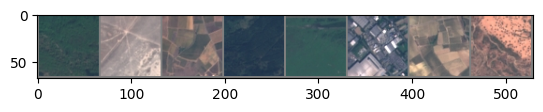

Labels: 1 2 6 1 5 4 6 2


In [21]:
# Mostra a imagem
mostra_imagem(torchvision.utils.make_grid(images[:8]))
print('Labels:', ' '.join('%d' % labels[j] for j in range(8)))